In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

In [2]:
# ============================================================
# Cell 2
# Project Paths
# ============================================================

from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

DATASET_ROOT = Path(r"D:\Research\Datasets\KITTI")

RESULT_DIR = PROJECT_ROOT / "results"

FIGURE_DIR = PROJECT_ROOT / "figures"

MODEL_DIR = PROJECT_ROOT / "models"

# ------------------------------------------------------------
# Create folders if they don't exist
# ------------------------------------------------------------

RESULT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("=" * 70)

print("Project Root :", PROJECT_ROOT)

print("Dataset Root :", DATASET_ROOT)

print("Results      :", RESULT_DIR)

print("Figures      :", FIGURE_DIR)

print("Models       :", MODEL_DIR)

print("=" * 70)

Project Root : D:\Research\Papers\Paper_2
Dataset Root : D:\Research\Datasets\KITTI
Results      : D:\Research\Papers\Paper_2\results
Figures      : D:\Research\Papers\Paper_2\figures
Models       : D:\Research\Papers\Paper_2\models


In [3]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.kitti_raw_dataset import KITTIRawDataset
from src.quality_metrics import CameraQualityMetrics

plt.rcParams["figure.figsize"] = (8,6)
plt.rcParams["figure.dpi"] = 120

In [4]:
# ============================================================
# Cell 3
# Initialize Dataset and Quality Metrics
# ============================================================

from src.kitti_raw_dataset import KITTIRawDataset
from src.quality_metrics import CameraQualityMetrics

DRIVE = "2011_09_26_drive_0001_sync"

DATASET = KITTIRawDataset(

    dataset_root=DATASET_ROOT,

    drive=DRIVE

)

QUALITY = CameraQualityMetrics()

print("=" * 70)

print("Dataset Initialized Successfully")

print("=" * 70)

DATASET.validate()

print()

print("Total Frames :", DATASET.get_frame_count())

Dataset Initialized Successfully
Drive                    : FOUND
Images                   : FOUND
OXTS                     : FOUND
Camera Calibration       : FOUND
IMU Calibration          : FOUND
Velodyne Calibration     : FOUND

Total Frames : 108


In [5]:
sample = DATASET.load_sample(
    frame=100
)

image = sample["image"]

gray = cv2.cvtColor(
    image,
    cv2.COLOR_RGB2GRAY
)

In [6]:
metrics = QUALITY.compute(gray)

metrics

{'Brightness': 95.5180418679549,
 'Contrast': 69.9362418000169,
 'Blur': 1066.150352495987,
 'Entropy': 7.336769104003906,
 'Dynamic Range': 250,
 'Edge Density': 0.15940526033279656,
 'Noise': 7.384512901306152}

In [7]:
metrics_df = pd.DataFrame(
    metrics.items(),
    columns=[
        "Metric",
        "Value"
    ]
)

display(metrics_df)

,Metric,Value
0,Brightness,95.518042
1,Contrast,69.936242
2,Blur,1066.150352
3,Entropy,7.336769
4,Dynamic Range,250.000000
5,Edge Density,0.159405
6,Noise,7.384513


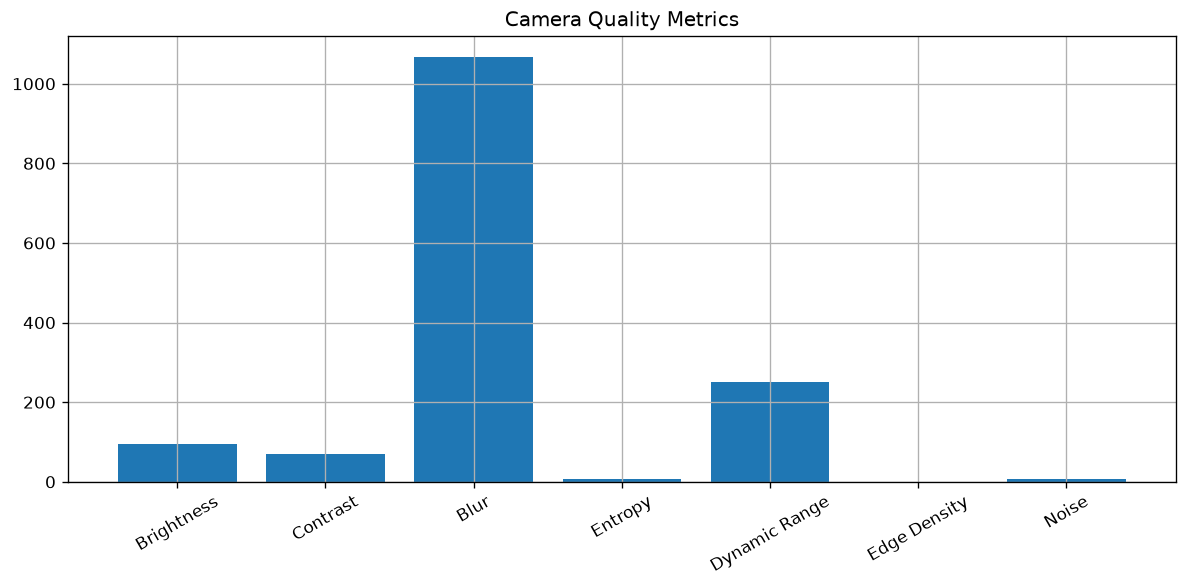

In [8]:
plt.figure(figsize=(10,5))

plt.bar(
    metrics_df["Metric"],
    metrics_df["Value"]
)

plt.title(
    "Camera Quality Metrics"
)

plt.xticks(rotation=30)

plt.grid(True)

plt.tight_layout()

plt.show()

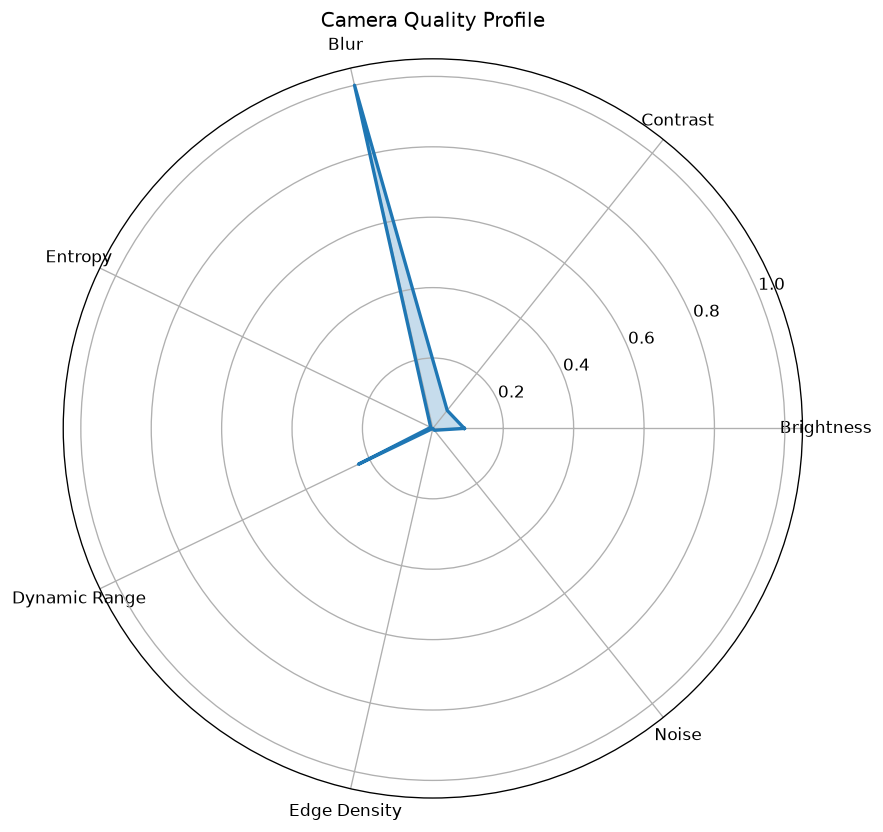

In [9]:
import numpy as np

metrics_norm = metrics_df.copy()

metrics_norm["Normalized"] = (
    metrics_norm["Value"] -
    metrics_norm["Value"].min()
) / (
    metrics_norm["Value"].max() -
    metrics_norm["Value"].min()
)

labels = metrics_norm["Metric"].tolist()

values = metrics_norm["Normalized"].tolist()

values += values[:1]

angles = np.linspace(
    0,
    2*np.pi,
    len(labels),
    endpoint=False
).tolist()

angles += angles[:1]

fig = plt.figure(figsize=(8,8))

ax = plt.subplot(111, polar=True)

ax.plot(
    angles,
    values,
    linewidth=2
)

ax.fill(
    angles,
    values,
    alpha=0.25
)

ax.set_xticks(angles[:-1])

ax.set_xticklabels(labels)

ax.set_title("Camera Quality Profile")

plt.show()

In [10]:
print("="*60)

print("Camera Quality Assessment")

print("="*60)

for metric, value in metrics.items():

    print(f"{metric:<20}: {value:.4f}")

print("="*60)

Camera Quality Assessment
Brightness          : 95.5180
Contrast            : 69.9362
Blur                : 1066.1504
Entropy             : 7.3368
Dynamic Range       : 250.0000
Edge Density        : 0.1594
Noise               : 7.3845


In [11]:
frame_count = DATASET.get_frame_count()

records = []

for frame in range(frame_count):

    sample = DATASET.load_sample(
        frame=frame
    )

    gray = cv2.cvtColor(
        sample["image"],
        cv2.COLOR_RGB2GRAY
    )

    result = QUALITY.compute(gray)

    result["Frame"] = frame

    records.append(result)

quality_df = pd.DataFrame(records)

display(quality_df.head())

print("=" * 60)
print("Total Frames Processed :", len(quality_df))
print("=" * 60)

,Brightness,Contrast,Blur,Entropy,Dynamic Range,Edge Density,Noise,Frame
0,88.167345,74.199336,733.457425,7.136627,251,0.108820,6.017031,0
1,86.974503,73.532517,725.276943,7.123037,250,0.109209,5.987283,1
2,85.261069,73.303896,714.558351,7.107850,250,0.110493,5.946865,2
3,85.619216,73.594935,713.989998,7.124490,252,0.112940,5.947129,3
4,87.901694,74.142102,740.824347,7.169953,252,0.116084,6.061246,4


Total Frames Processed : 108


In [12]:
quality_df.describe()

,Brightness,Contrast,Blur,Entropy,Dynamic Range,Edge Density,Noise,Frame
count,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,108.00000
mean,90.285057,72.002850,891.562477,7.232659,250.601852,0.123533,6.676942,53.50000
std,3.677124,2.474153,148.948040,0.089295,0.975780,0.023378,0.594013,31.32092
min,82.779830,67.364611,668.508891,7.057907,248.000000,0.095768,5.748700,0.00000
25%,87.339094,70.455119,777.482104,7.143026,250.000000,0.105173,6.248519,26.75000
50%,89.992701,71.993847,838.468155,7.253877,251.000000,0.110496,6.484376,53.50000
75%,93.126622,74.251556,1035.260876,7.312872,251.000000,0.147228,7.267557,80.25000
max,97.645445,75.654453,1196.888715,7.365297,254.000000,0.169651,7.822153,107.00000


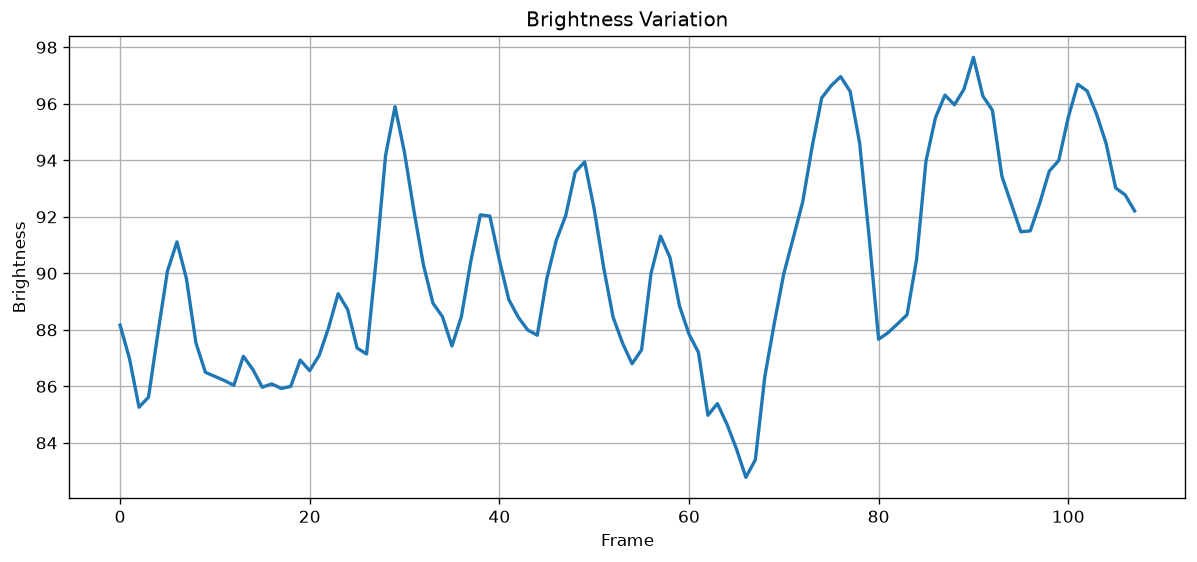

In [13]:
plt.figure(figsize=(12,5))

plt.plot(
    quality_df["Frame"],
    quality_df["Brightness"],
    linewidth=2
)

plt.title("Brightness Variation")

plt.xlabel("Frame")

plt.ylabel("Brightness")

plt.grid(True)

plt.show()

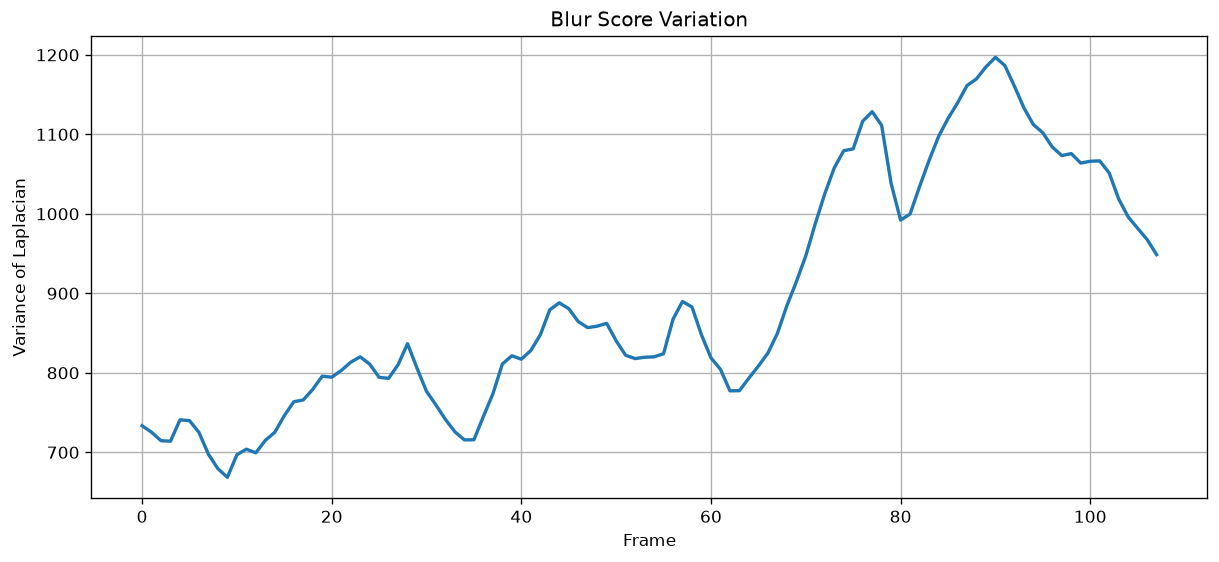

In [14]:
plt.figure(figsize=(12,5))

plt.plot(
    quality_df["Frame"],
    quality_df["Blur"],
    linewidth=2
)

plt.title("Blur Score Variation")

plt.xlabel("Frame")

plt.ylabel("Variance of Laplacian")

plt.grid(True)

plt.show()

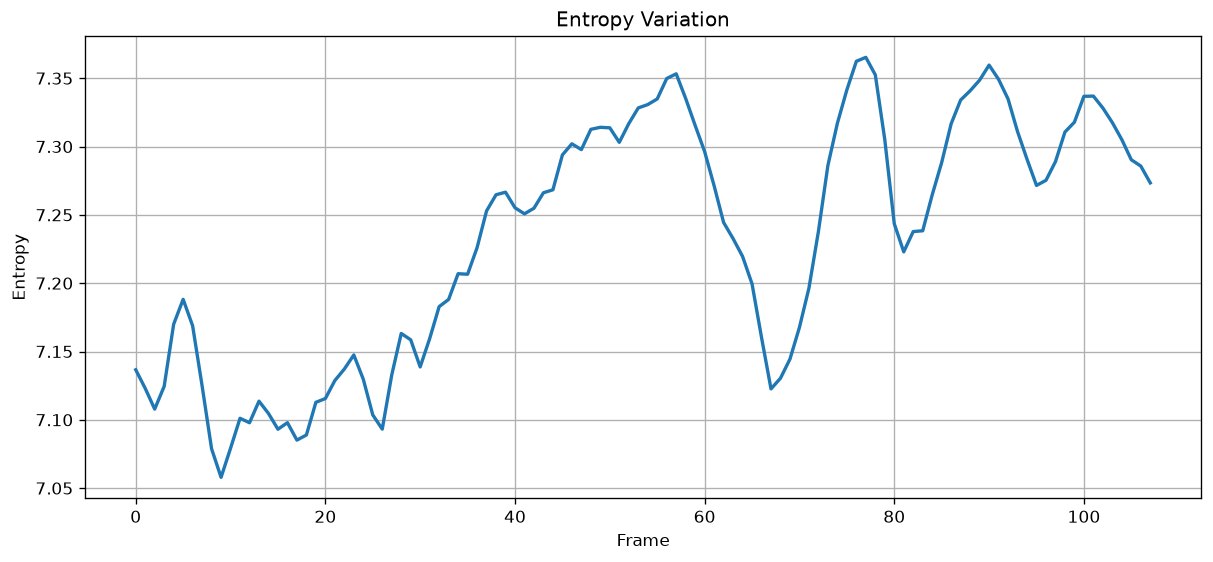

In [15]:
plt.figure(figsize=(12,5))

plt.plot(
    quality_df["Frame"],
    quality_df["Entropy"],
    linewidth=2
)

plt.title("Entropy Variation")

plt.xlabel("Frame")

plt.ylabel("Entropy")

plt.grid(True)

plt.show()

,Brightness,Contrast,Blur,Entropy,Dynamic Range,Edge Density,Noise
Brightness,1.000000,-0.103784,0.731382,0.667272,-0.120523,0.687506,0.717242
Contrast,-0.103784,1.000000,-0.385133,-0.607324,0.153377,-0.384163,-0.424591
Blur,0.731382,-0.385133,1.000000,0.709997,-0.150999,0.939927,0.998385
Entropy,0.667272,-0.607324,0.709997,1.000000,-0.146773,0.561825,0.718957
Dynamic Range,-0.120523,0.153377,-0.150999,-0.146773,1.000000,-0.116674,-0.150621
Edge Density,0.687506,-0.384163,0.939927,0.561825,-0.116674,1.000000,0.939312
Noise,0.717242,-0.424591,0.998385,0.718957,-0.150621,0.939312,1.000000


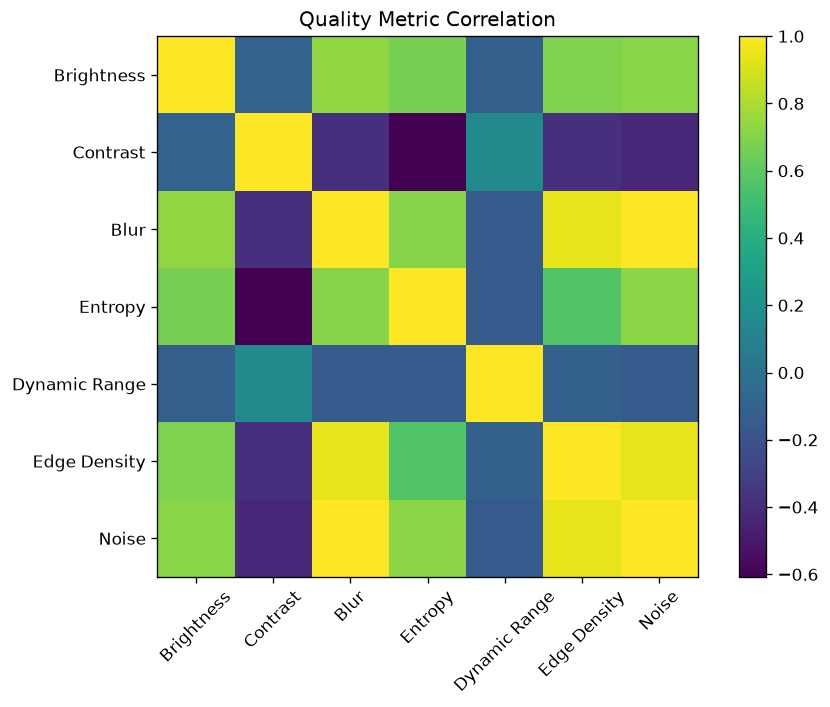

In [16]:
corr = quality_df.drop(columns=["Frame"]).corr()

display(corr)

plt.figure(figsize=(8,6))

plt.imshow(corr)

plt.colorbar()

plt.xticks(
    range(len(corr.columns)),
    corr.columns,
    rotation=45
)

plt.yticks(
    range(len(corr.columns)),
    corr.columns
)

plt.title("Quality Metric Correlation")

plt.tight_layout()

plt.show()

In [18]:
# ============================================================
# Cell 16
# Save Results
# ============================================================

# ------------------------------------------------------------
# Save Complete Quality Metrics
# ------------------------------------------------------------

quality_df.to_csv(

    RESULT_DIR / f"camera_quality_metrics_{DRIVE}.csv",

    index=False

)

# ------------------------------------------------------------
# Save Statistics
# ------------------------------------------------------------

statistics = quality_df.describe()

statistics.to_csv(

    RESULT_DIR / f"camera_quality_statistics_{DRIVE}.csv"

)

# ------------------------------------------------------------
# Console Output
# ------------------------------------------------------------

print("=" * 80)

print("NOTEBOOK 04 COMPLETED SUCCESSFULLY")

print("=" * 80)

print()

print("Drive :", DRIVE)

print("Frames Processed :", len(quality_df))

print()

print("Generated Files")

print("------------------------------")

print(f"camera_quality_metrics_{DRIVE}.csv")

print(f"camera_quality_statistics_{DRIVE}.csv")

print()

print("Average Brightness :", round(quality_df["Brightness"].mean(), 2))

print("Average Contrast   :", round(quality_df["Contrast"].mean(), 2))

print("Average Blur Score :", round(quality_df["Blur"].mean(), 2))

print()

print("READY FOR NOTEBOOK 05")

print("=" * 80)

NOTEBOOK 04 COMPLETED SUCCESSFULLY

Drive : 2011_09_26_drive_0001_sync
Frames Processed : 108

Generated Files
------------------------------
camera_quality_metrics_2011_09_26_drive_0001_sync.csv
camera_quality_statistics_2011_09_26_drive_0001_sync.csv

Average Brightness : 90.29
Average Contrast   : 72.0
Average Blur Score : 891.56

READY FOR NOTEBOOK 05


In [19]:
# ============================================================
# Final Summary
# ============================================================

print("=" * 80)

print("NOTEBOOK 04 COMPLETED SUCCESSFULLY")

print("=" * 80)

print()

print("Drive :", DRIVE)

print("Frames Processed :", len(quality_df))

print()

print("Average Brightness :", round(quality_df["Brightness"].mean(), 2))

print("Average Contrast   :", round(quality_df["Contrast"].mean(), 2))

print("Average Blur Score :", round(quality_df["Blur"].mean(), 2))

print()

print("Generated Files")

print("-----------------------------")

print(f"camera_quality_metrics_{DRIVE}.csv")

print(f"camera_quality_statistics_{DRIVE}.csv")

print()

print("READY FOR NOTEBOOK 05")

print("=" * 80)

NOTEBOOK 04 COMPLETED SUCCESSFULLY

Drive : 2011_09_26_drive_0001_sync
Frames Processed : 108

Average Brightness : 90.29
Average Contrast   : 72.0
Average Blur Score : 891.56

Generated Files
-----------------------------
camera_quality_metrics_2011_09_26_drive_0001_sync.csv
camera_quality_statistics_2011_09_26_drive_0001_sync.csv

READY FOR NOTEBOOK 05
